# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : YUAN KANEZAR
- NIM   : 241011402720
- Kelas : Reg CS

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [29]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 20

In [30]:

def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size harus di antara 0 dan 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 data pertama:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40

Shape X: (40, 1)
Shape y: (40,)


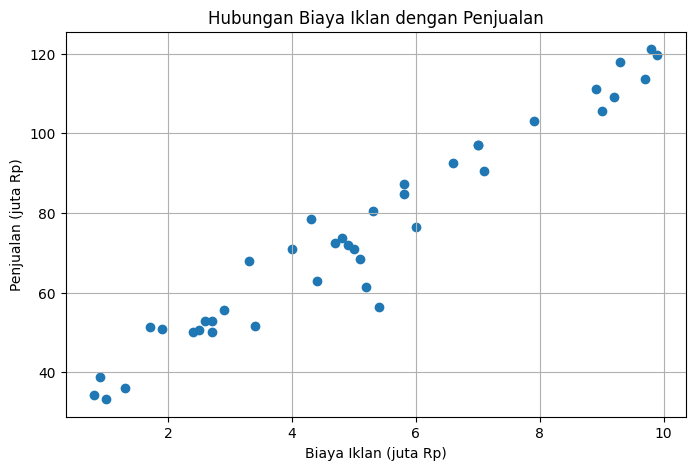

In [31]:

df_ads = pd.read_csv("Ads_Data.csv")

print("5 data pertama:")
print(df_ads.head())

print("\nJumlah baris data:", len(df_ads))

# Memisahkan fitur X dan target y
X = df_ads[["BiayaIklan"]].to_numpy()
y = df_ads["Penjualan"].to_numpy()

print("\nShape X:", X.shape)
print("Shape y:", y.shape)

# Membuat scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], y)
plt.title("Hubungan Biaya Iklan dengan Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(True)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [32]:


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

print("\nShape X_train:", X_train.shape)
print("Shape X_test:", X_test.shape)
print("Shape y_train:", y_train.shape)
print("Shape y_test:", y_test.shape)

Jumlah data training: 32
Jumlah data testing: 8

Shape X_train: (32, 1)
Shape X_test: (8, 1)
Shape y_train: (32,)
Shape y_test: (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [33]:

X_train_bias = np.c_[np.ones(len(X_train)), X_train]

theta = np.linalg.inv(X_train_bias.T @ X_train_bias) @ X_train_bias.T @ y_train

intercept = theta[0]
koefisien = theta[1]

print("Intercept:", intercept)
print("Koefisien:", koefisien)
print(f"Persamaan regresi: y = {intercept:.4f} + {koefisien:.4f}x")


Intercept: 26.950878486366598
Koefisien: 9.313010208199927
Persamaan regresi: y = 26.9509 + 9.3130x


**Jawaban A3 (interpretasi):**

Intercept = 26.9509: Menunjukkan estimasi tingkat penjualan sebesar Rp26,95 juta ketika toko tidak mengeluarkan biaya iklan sama sekali ($X = 0$).   Koefisien (= 9.3130$): Nilai positif ini menandakan bahwa setiap penambahan biaya iklan sebesar Rp1 juta, diperkirakan akan meningkatkan angka penjualan sebesar Rp9,31 juta.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [34]:

def predict_linear(X_data):
    X_bias = np.c_[np.ones(len(X_data)), X_data]
    return X_bias @ theta

# Fungsi evaluasi model
def evaluasi_regresi(y_asli, y_prediksi):
    mae = np.mean(np.abs(y_asli - y_prediksi))
    mse = np.mean((y_asli - y_prediksi) ** 2)
    rmse = np.sqrt(mse)

    ss_res = np.sum((y_asli - y_prediksi) ** 2)
    ss_tot = np.sum((y_asli - np.mean(y_asli)) ** 2)
    r2 = 1 - (ss_res / ss_tot)

    return mae, mse, rmse, r2

# Prediksi data training dan testing
y_train_pred = predict_linear(X_train)
y_test_pred = predict_linear(X_test)

# Menghitung metrik evaluasi
hasil_train = evaluasi_regresi(y_train, y_train_pred)
hasil_test = evaluasi_regresi(y_test, y_test_pred)

# Menampilkan hasil dalam tabel
tabel_evaluasi = pd.DataFrame({
    "Metrik": ["MAE", "MSE", "RMSE", "R2"],
    "Training": hasil_train,
    "Testing": hasil_test
})

print("Hasil Evaluasi Model:")
print(tabel_evaluasi.to_string(index=False))


Hasil Evaluasi Model:
Metrik  Training   Testing
   MAE  4.286647  5.429557
   MSE 37.290943 32.706541
  RMSE  6.106631  5.718963
    R2  0.944082  0.933403


**Jawaban A4 (analisis):**

Berdasarkan hasil evaluasi, nilai MAE, MSE, dan RMSE digunakan untuk mengukur besar kesalahan prediksi model. Semakin kecil nilai ketiga metrik tersebut, semakin baik hasil prediksinya. Sementara itu, nilai R² menunjukkan seberapa baik model menjelaskan variasi data penjualan. Hasil evaluasi training dan testing dibandingkan untuk mengetahui kemampuan model pada data yang sudah dipelajari dan data yang belum pernah dilihat. Jika hasil testing jauh lebih buruk daripada training, model kemungkinan kurang mampu memprediksi data baru dengan baik.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*


Learning rate: 0.001
Intercept: 26.953042111624818
Koefisien: 9.312591610810193
Loss akhir: 0.055918
Selisih koefisien dari Normal Equation: 0.00041859738973393235

Learning rate: 0.02
Intercept: 26.95087848636671
Koefisien: 9.31301020819991
Loss akhir: 0.055918
Selisih koefisien dari Normal Equation: 1.5987211554602254e-14

Learning rate: 0.1
Intercept: 26.950878486366662
Koefisien: 9.313010208199922
Loss akhir: 0.055918
Selisih koefisien dari Normal Equation: 5.329070518200751e-15


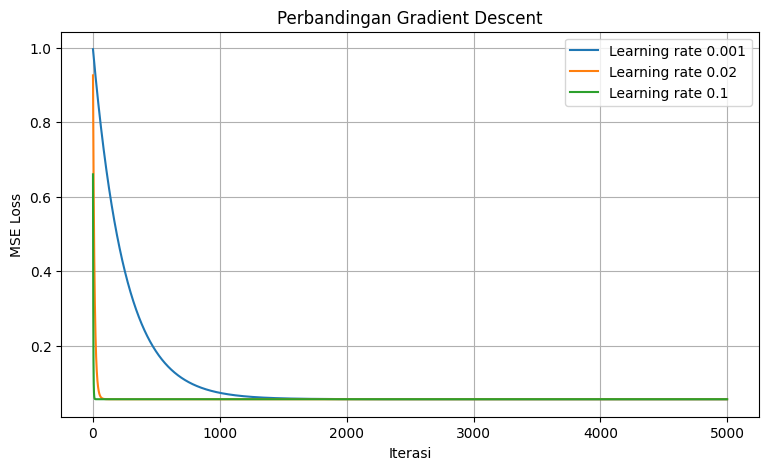

In [35]:


x_mean = np.mean(X_train)
x_std = np.std(X_train)
y_mean = np.mean(y_train)
y_std = np.std(y_train)

X_train_scaled = (X_train - x_mean) / x_std
y_train_scaled = (y_train - y_mean) / y_std

def gradient_descent(X_data, y_data, learning_rate, iterations):
    X_bias = np.c_[np.ones(len(X_data)), X_data]
    m = len(y_data)
    theta_gd = np.zeros(X_bias.shape[1])
    loss_history = []

    for i in range(iterations):
        error = X_bias @ theta_gd - y_data
        gradient = (2 / m) * (X_bias.T @ error)
        theta_gd -= learning_rate * gradient
        loss = np.mean((X_bias @ theta_gd - y_data) ** 2)
        loss_history.append(loss)

    return theta_gd, loss_history

learning_rates = [0.001, 0.02, 0.1]
hasil_gd = {}

for lr in learning_rates:
    theta_scaled, loss_history = gradient_descent(
        X_train_scaled, y_train_scaled, lr, 5000
    )

    koef_gd = theta_scaled[1] * y_std / x_std
    intercept_gd = y_mean + y_std * theta_scaled[0] - koef_gd * x_mean

    hasil_gd[lr] = loss_history

    print(f"\nLearning rate: {lr}")
    print("Intercept:", intercept_gd)
    print("Koefisien:", koef_gd)
    print("Loss akhir:", round(loss_history[-1], 6))
    print("Selisih koefisien dari Normal Equation:",
          abs(koef_gd - koefisien))

plt.figure(figsize=(9, 5))

for lr in learning_rates:
    plt.plot(hasil_gd[lr], label=f"Learning rate {lr}")

plt.title("Perbandingan Gradient Descent")
plt.xlabel("Iterasi")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()


**Jawaban A5 (analisis):**


Pada percobaan Gradient Descent, saya menggunakan tiga nilai learning rate, yaitu 0.001, 0.02, dan 0.1, dengan 5000 iterasi. Perbedaan learning rate memengaruhi kecepatan model dalam mencapai nilai loss yang kecil. Learning rate yang tepat akan membuat proses pembelajaran lebih cepat dan stabil, sedangkan nilai yang kurang tepat dapat membuat proses pembelajaran lebih lambat atau tidak stabil.

Hasil terbaik dapat dilihat dari grafik dan nilai loss akhir. Semakin kecil nilai loss, semakin kecil kesalahan prediksi model terhadap data latihan. Nilai intercept dan koefisien dari Gradient Descent juga dibandingkan dengan metode Normal Equation untuk melihat apakah hasil keduanya mendekati.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

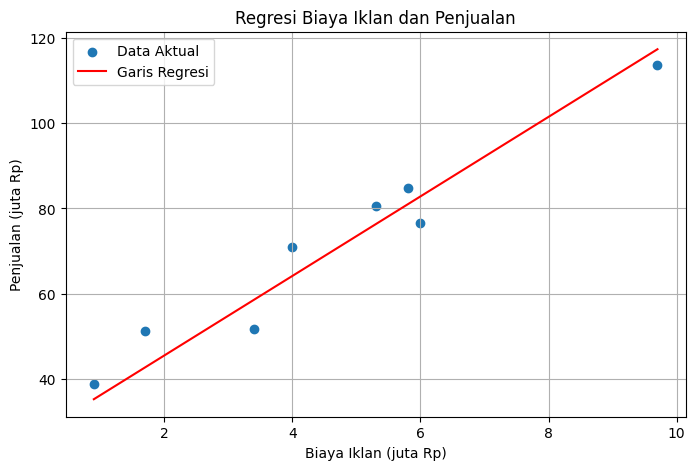

Biaya iklan 4.5 juta -> Prediksi penjualan 68.8594 juta
Biaya iklan 7.0 juta -> Prediksi penjualan 92.1419 juta
Biaya iklan 12.0 juta -> Prediksi penjualan 138.7070 juta


In [36]:

y_test_pred = predict_linear(X_test)

# Membuat grafik
plt.figure(figsize=(8, 5))
plt.scatter(X_test[:, 0], y_test, label="Data Aktual")

urutan = np.argsort(X_test[:, 0])
plt.plot(
    X_test[urutan, 0],
    y_test_pred[urutan],
    color="red",
    label="Garis Regresi"
)

plt.title("Regresi Biaya Iklan dan Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.grid(True)
plt.show()

# Prediksi penjualan
biaya_iklan = np.array([[4.5], [7], [12]])
hasil_prediksi = predict_linear(biaya_iklan)

for x, prediksi in zip(biaya_iklan[:, 0], hasil_prediksi):
    print(f"Biaya iklan {x} juta -> Prediksi penjualan {prediksi:.4f} juta")


**Jawaban A6 (analisis):**

Grafik menunjukkan hubungan antara biaya iklan dan penjualan berdasarkan garis regresi yang diperoleh dari model. Model digunakan untuk memprediksi penjualan ketika biaya iklan sebesar Rp4,5 juta, Rp7 juta, dan Rp12 juta. Prediksi yang masih berada dalam rentang data disebut interpolasi, sedangkan prediksi di luar rentang data disebut ekstrapolasi. Hasil ekstrapolasi perlu diperhatikan karena belum tentu sesuai dengan kondisi sebenarnya.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 data pertama:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah email berdasarkan kelas:
Bukan Spam (0): 35
Spam (1): 25

Shape X: (60, 2)
Shape y: (60,)


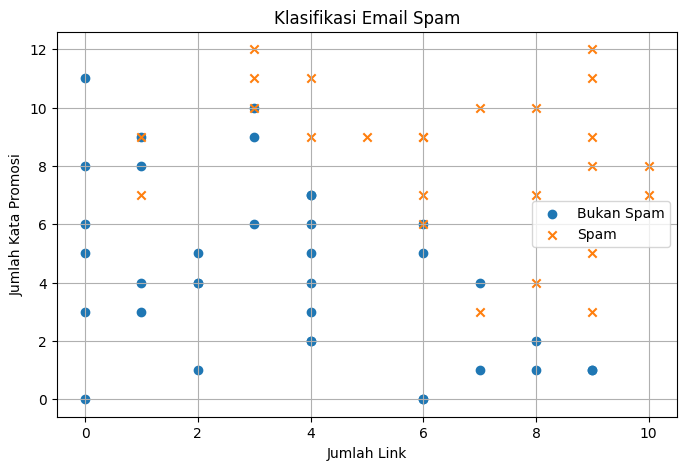

In [37]:

df_email = pd.read_csv("Email_Data.csv")

print("5 data pertama:")
print(df_email.head())

print("\nJumlah email berdasarkan kelas:")
print("Bukan Spam (0):", (df_email["Spam"] == 0).sum())
print("Spam (1):", (df_email["Spam"] == 1).sum())

X_email = df_email[["JumlahLink", "KataPromo"]].to_numpy()
y_email = df_email["Spam"].to_numpy()
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email,
    y_email,
    test_size=0.2,
    random_state=RANDOM_STATE
)
print("\nShape X:", X_email.shape)
print("Shape y:", y_email.shape)

plt.figure(figsize=(8, 5))

bukan_spam = df_email[df_email["Spam"] == 0]
spam = df_email[df_email["Spam"] == 1]

plt.scatter(
    bukan_spam["JumlahLink"],
    bukan_spam["KataPromo"],
    label="Bukan Spam",
    marker="o"
)

plt.scatter(
    spam["JumlahLink"],
    spam["KataPromo"],
    label="Spam",
    marker="x"
)

plt.title("Klasifikasi Email Spam")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promosi")
plt.legend()
plt.grid(True)
plt.show()


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Bobot: [0.78466323 0.76426461]
Bias: -9.086788537968681
Persamaan model: z = -9.0868 + (0.7847 × JumlahLink) + (0.7643 × KataPromo)


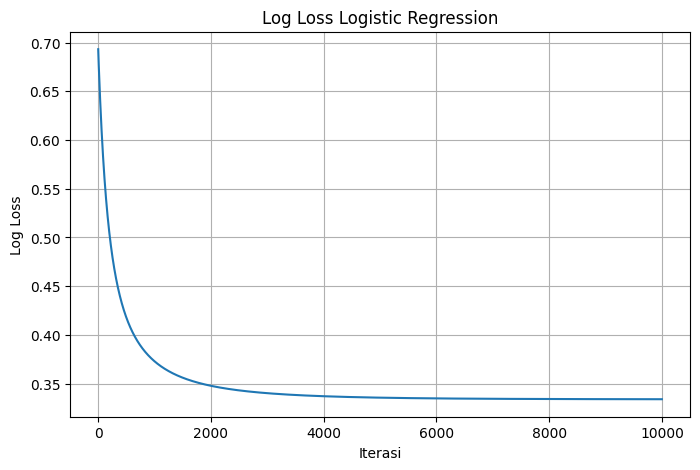

In [38]:

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def train_logistic_regression(X, y, learning_rate=0.1, n_iterations=10000):
    m, n = X.shape
    weights = np.zeros(n)
    bias = 0.0
    loss_history = []

    for i in range(n_iterations):
        z = X @ weights + bias
        y_pred = sigmoid(z)

        epsilon = 1e-15
        loss = -np.mean(
            y * np.log(y_pred + epsilon)
            + (1 - y) * np.log(1 - y_pred + epsilon)
        )
        loss_history.append(loss)

        dw = (X.T @ (y_pred - y)) / m
        db = np.mean(y_pred - y)

        weights -= learning_rate * dw
        bias -= learning_rate * db

    return weights, bias, loss_history

weights, bias, loss_history = train_logistic_regression(
    X_train_email,
    y_train_email,
    learning_rate=0.1,
    n_iterations=10000
)

print("Bobot:", weights)
print("Bias:", bias)
print("Persamaan model: z = "
      f"{bias:.4f} + ({weights[0]:.4f} × JumlahLink)"
      f" + ({weights[1]:.4f} × KataPromo)")

plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.title("Log Loss Logistic Regression")
plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.grid(True)
plt.show()


**Jawaban B2 (analisis):**


Pada tahap ini, data Email dibagi menjadi data training sebanyak 45 data dan data testing sebanyak 15 data. Model Logistic Regression dilatih menggunakan metode Gradient Descent dengan learning rate 0.1 dan 10.000 iterasi. Proses pembelajaran dapat diamati melalui grafik log loss. Jika nilai log loss semakin menurun, berarti kesalahan model pada data training semakin kecil. Nilai bobot dan bias yang diperoleh digunakan untuk membentuk persamaan model dalam memprediksi apakah sebuah email termasuk spam atau bukan spam.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [39]:

y_prob = sigmoid(X_test_email @ weights + bias)
y_pred = (y_prob >= 0.5).astype(int)

# Confusion Matrix
TN = np.sum((y_test_email == 0) & (y_pred == 0))
FP = np.sum((y_test_email == 0) & (y_pred == 1))
FN = np.sum((y_test_email == 1) & (y_pred == 0))
TP = np.sum((y_test_email == 1) & (y_pred == 1))

accuracy = (TP + TN) / len(y_test_email)
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0

print("Confusion Matrix:")
print(np.array([[TN, FP], [FN, TP]]))
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))


Confusion Matrix:
[[5 0]
 [0 7]]
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0


**Jawaban B3 (analisis):**

Evaluasi model dilakukan menggunakan data testing untuk mengetahui kemampuan Logistic Regression dalam mengklasifikasikan email spam dan bukan spam. Confusion Matrix menunjukkan jumlah prediksi yang benar dan salah. Accuracy mengukur persentase seluruh prediksi yang benar, precision mengukur ketepatan prediksi spam, sedangkan recall mengukur kemampuan model dalam menemukan email spam yang sebenarnya. Semakin baik nilai evaluasi tersebut, semakin baik kemampuan model dalam melakukan klasifikasi.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

In [40]:

if abs(weights[1]) > 1e-10:
    print(
        f"Persamaan batas keputusan: "
        f"KataPromo = {-bias / weights[1]:.4f} "
        f"- ({weights[0] / weights[1]:.4f} × JumlahLink)"
    )
else:
    print("Batas keputusan tidak dapat ditampilkan sebagai garis tersebut.")


Persamaan batas keputusan: KataPromo = 11.8896 - (1.0267 × JumlahLink)


**Jawaban B4 (analisis):**

Visualisasi Decision Boundary digunakan untuk melihat bagaimana model Logistic Regression memisahkan email spam dan bukan spam berdasarkan jumlah link dan kata promo. Setiap titik mewakili data email, sedangkan warna pada grafik menunjukkan wilayah prediksi model. Batas keputusan ditentukan berdasarkan probabilitas 0,5. Titik yang berada pada wilayah klasifikasi yang berbeda menunjukkan perbedaan hasil prediksi model terhadap kategori email.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [41]:

probabilitas = sigmoid(X_test_email @ weights + bias)
hasil_threshold = []

for threshold in [0.3, 0.5, 0.7]:
    prediksi = (probabilitas >= threshold).astype(int)

    tn = np.sum((y_test_email == 0) & (prediksi == 0))
    fp = np.sum((y_test_email == 0) & (prediksi == 1))
    fn = np.sum((y_test_email == 1) & (prediksi == 0))
    tp = np.sum((y_test_email == 1) & (prediksi == 1))

    accuracy = (tp + tn) / len(y_test_email)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    hasil_threshold.append({
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall
    })

tabel_threshold = pd.DataFrame(hasil_threshold)

print("Hasil Evaluasi Berbagai Threshold:")
print(tabel_threshold.round(4).to_string(index=False))


Hasil Evaluasi Berbagai Threshold:
 Threshold  TN  FP  FN  TP  Accuracy  Precision  Recall
       0.3   5   0   0   7       1.0        1.0     1.0
       0.5   5   0   0   7       1.0        1.0     1.0
       0.7   5   0   0   7       1.0        1.0     1.0


**Jawaban B5 (analisis):**

Threshold yang lebih rendah membuat model lebih mudah mengklasifikasikan email sebagai spam, sehingga recall cenderung meningkat, tetapi false positive juga dapat bertambah. Sebaliknya, threshold yang lebih tinggi membuat model lebih selektif dalam menentukan spam, sehingga precision dapat meningkat, tetapi beberapa email spam mungkin tidak terdeteksi. Saya memilih threshold berdasarkan hasil confusion matrix, precision, dan recall pada tabel pengujian. Untuk filter spam, saya mempertimbangkan agar email penting tidak salah masuk kategori spam, sekaligus tetap mampu mendeteksi email yang benar-benar spam.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [42]:

threshold_pilihan = 0.5

email_baru = np.array([
    [1, 2],
    [5, 6],
    [9, 10],
    [2, 11]
])

probabilitas_baru = sigmoid(email_baru @ weights + bias)

prediksi_baru = (probabilitas_baru >= threshold_pilihan).astype(int)

for i in range(len(email_baru)):
    status = "Spam" if prediksi_baru[i] == 1 else "Bukan Spam"

    print(f"Email {i+1}:")
    print(f"  Jumlah Link       : {email_baru[i, 0]}")
    print(f"  Kata Promo        : {email_baru[i, 1]}")
    print(f"  Probabilitas Spam : {probabilitas_baru[i]:.4f}")
    print(f"  Hasil Prediksi    : {status}")
    print()


Email 1:
  Jumlah Link       : 1
  Kata Promo        : 2
  Probabilitas Spam : 0.0011
  Hasil Prediksi    : Bukan Spam

Email 2:
  Jumlah Link       : 5
  Kata Promo        : 6
  Probabilitas Spam : 0.3594
  Hasil Prediksi    : Bukan Spam

Email 3:
  Jumlah Link       : 9
  Kata Promo        : 10
  Probabilitas Spam : 0.9964
  Hasil Prediksi    : Spam

Email 4:
  Jumlah Link       : 2
  Kata Promo        : 11
  Probabilitas Spam : 0.7088
  Hasil Prediksi    : Spam



---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression termasuk algoritma klasifikasi karena digunakan untuk menentukan kategori suatu data, misalnya email spam atau bukan spam. Fungsi sigmoid mengubah hasil perhitungan model menjadi nilai probabilitas antara 0 dan 1. Nilai tersebut kemudian dibandingkan dengan threshold untuk menentukan kelas prediksi. Contohnya, jika probabilitas mencapai 0,5 atau lebih, email dikategorikan sebagai spam.

**Jawaban C2:** Normal Equation menghitung koefisien regresi secara langsung menggunakan rumus matematika tanpa proses iterasi. Sementara itu, Gradient Descent mencari koefisien terbaik secara bertahap dengan memperbarui nilainya berulang kali. Normal Equation cocok untuk dataset yang relatif kecil dan jumlah fitur yang tidak terlalu banyak. Gradient Descent lebih cocok untuk dataset besar karena dapat menghitung solusi secara bertahap, meskipun membutuhkan pengaturan learning rate dan jumlah iterasi.

**Jawaban C3:** Data testing digunakan untuk mengukur kemampuan model dalam memprediksi data yang belum pernah dipelajari. Jika hanya menggunakan data training, hasil evaluasi belum tentu menggambarkan kemampuan model pada data baru. Overfitting adalah kondisi ketika model terlalu menyesuaikan diri dengan data training sehingga kurang baik saat memprediksi data baru. Oleh karena itu, data testing diperlukan untuk menilai kemampuan model secara lebih objektif.

**Jawaban C4:** Linear Regression menggunakan MSE untuk mengukur rata-rata kuadrat selisih antara nilai prediksi dan nilai sebenarnya. Model ini menghasilkan nilai numerik yang dapat dibandingkan langsung dengan target. Logistic Regression menggunakan log loss karena menghasilkan probabilitas untuk setiap kelas. Log loss mengukur seberapa baik probabilitas prediksi sesuai dengan kelas sebenarnya dan memberikan penalti besar ketika model sangat yakin terhadap prediksi yang salah.

**Jawaban C5:** Hasil dapat berbeda karena pembagian data training dan testing menggunakan nilai random state yang berbeda. Pengaturan learning rate, jumlah iterasi, dan bobot awal juga dapat memengaruhi hasil training. Selain itu, perbedaan cara implementasi algoritma atau proses pengolahan data dapat menghasilkan koefisien dan metrik evaluasi yang berbeda. Agar hasil lebih konsisten, pengaturan dan langkah pengolahan data harus dibuat sama.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [43]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Melatih model Linear Regression Scikit-learn
model_linear_sklearn = LinearRegression()
model_linear_sklearn.fit(X_train, y_train)

# Prediksi dari kedua model
pred_linear_manual = predict_linear(X_test)
pred_linear_sklearn = model_linear_sklearn.predict(X_test)

print("=== Perbandingan Linear Regression ===")

print("\nKoefisien manual:", koefisien)
print("Intercept manual:", intercept)

print("\nKoefisien sklearn:", model_linear_sklearn.coef_[0])
print("Intercept sklearn:", model_linear_sklearn.intercept_)

print("\nEvaluasi Model Manual:")
print("MAE :", round(mean_absolute_error(y_test, pred_linear_manual), 4))
print("MSE :", round(mean_squared_error(y_test, pred_linear_manual), 4))
print("R2  :", round(r2_score(y_test, pred_linear_manual), 4))

print("\nEvaluasi Model Scikit-learn:")
print("MAE :", round(mean_absolute_error(y_test, pred_linear_sklearn), 4))
print("MSE :", round(mean_squared_error(y_test, pred_linear_sklearn), 4))
print("R2  :", round(r2_score(y_test, pred_linear_sklearn), 4))


=== Perbandingan Linear Regression ===

Koefisien manual: 9.313010208199927
Intercept manual: 26.950878486366598

Koefisien sklearn: 9.313010208199925
Intercept sklearn: 26.95087848636664

Evaluasi Model Manual:
MAE : 5.4296
MSE : 32.7065
R2  : 0.9334

Evaluasi Model Scikit-learn:
MAE : 5.4296
MSE : 32.7065
R2  : 0.9334


In [44]:


from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model_sklearn = LogisticRegression(max_iter=10000, random_state=RANDOM_STATE)
model_sklearn.fit(X_train_email, y_train_email)

pred_manual = (sigmoid(X_test_email @ weights + bias) >= 0.5).astype(int)
pred_sklearn = model_sklearn.predict(X_test_email)

akurasi_manual = accuracy_score(y_test_email, pred_manual)
akurasi_sklearn = accuracy_score(y_test_email, pred_sklearn)

print("=== Perbandingan Model ===")
print("Akurasi Logistic Regression manual:", round(akurasi_manual, 4))
print("Akurasi Logistic Regression sklearn:", round(akurasi_sklearn, 4))

print("\nKoefisien model manual:", weights)
print("Bias model manual:", bias)

print("\nKoefisien model sklearn:", model_sklearn.coef_[0])
print("Intercept model sklearn:", model_sklearn.intercept_[0])


=== Perbandingan Model ===
Akurasi Logistic Regression manual: 1.0
Akurasi Logistic Regression sklearn: 1.0

Koefisien model manual: [0.78466323 0.76426461]
Bias model manual: -9.086788537968681

Koefisien model sklearn: [0.72444153 0.71259124]
Intercept model sklearn: -8.464374590474245


**Jawaban Bonus (analisis):**


Perbandingan dilakukan untuk melihat perbedaan hasil Logistic Regression buatan sendiri dengan Scikit-learn. Kedua model menggunakan data training dan testing yang sama. Hasil akurasi dan koefisien dapat berbeda karena metode optimasi serta pengaturan model yang digunakan berbeda. Scikit-learn menyediakan implementasi yang sudah dioptimalkan, sedangkan model manual menggunakan Gradient Descent yang dibuat sendiri.